# Perfil do eleitorado × voto por partido, país inteiro

A unidade de análise é a **zona eleitoral × município** (`id_zona_mun`). Cada
município com uma só zona é uma unidade; os municípios com várias zonas (capitais
e cidades grandes) têm uma unidade por zona.

- **Voto e escolaridade são observados**: soma dos locais de votação da zona
  (o voto bate com o publicado pelo TSE por zona). A escolaridade é a do cadastro
  eleitoral.
- **A renda é estimada**: renda média do responsável pelo domicílio (Censo 2022),
  levada dos setores à área de cada local de votação pela matriz de pesos do
  CNEFE e depois à zona (média dos locais ponderada pelos adultos).

A tabela vem de `python scripts/10_perfil_voto_municipio.py --ano 2022` (sem
`--cd-mun`). Para um município de cada vez, com locais e setores, usar
`perfil_voto_municipio.ipynb`.

**Como ler os resultados**

- Os dados são agregados: mostram **onde** cada partido vai melhor, não como vota
  cada pessoa. É a chamada falácia ecológica.
- Os quintis abaixo dividem o **eleitorado** em cinco partes de mesmo tamanho (não
  as unidades): Q1 reúne 20% dos eleitores que vivem nas unidades menos
  escolarizadas ou mais pobres.
- A escolaridade do cadastro é a declarada no alistamento e quase nunca é
  atualizada: subestima a escolaridade atual.
- A renda por zona herda a imprecisão da distribuição dos setores para os locais.
  Nos municípios de uma só zona ela é a renda do município inteiro.
- O voto para deputado segue o candidato e o reduto dele; a soma por partido
  mistura bases pessoais diferentes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

ANO = 2022
PC_MINIMO_PARTIDO = 0.03  # partido abaixo disso (nacional) entra em "Outros"

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
ANALISE = RAIZ / "dados" / "04_analise" / "BR"

CODIGOS_NAO_CANDIDATO = (95, 96, 97)
DISPUTAS = {
    "pres_t1": "Presidente, 1º turno",
    "pres_t2": "Presidente, 2º turno",
    "depfed_t1": "Deputado Federal",
}
QUINTIS = [f"Q{i}" for i in range(1, 6)]
REGIAO = {"1": "Norte", "2": "Nordeste", "3": "Sudeste", "4": "Sul", "5": "Centro-Oeste"}

pd.set_option("display.max_columns", 40)

In [2]:
# ==== Aparência dos gráficos ==================================================
COR = "#2a78d6"  # série única
COR_TINTA = "#0b0b0b"
COR_TINTA_2 = "#52514e"
COR_SUAVE = "#898781"
COR_GRADE = "#e1e0d9"
COR_EIXO = "#c3c2b7"
COR_FUNDO = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": COR_FUNDO, "axes.facecolor": COR_FUNDO, "savefig.facecolor": COR_FUNDO,
    "figure.dpi": 110,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": COR_TINTA, "axes.labelcolor": COR_TINTA_2,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": COR_EIXO, "ytick.color": COR_EIXO,
    "xtick.labelcolor": COR_SUAVE, "ytick.labelcolor": COR_SUAVE,
    "axes.edgecolor": COR_EIXO, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": COR_GRADE, "grid.linewidth": 0.6,
})


def numero(valor: float, casas: int = 1) -> str:
    return f"{valor:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

## Dados

In [3]:
todas = pd.read_parquet(ANALISE / f"perfil_voto_zona_mun_{ANO}.parquet")
SIGLA = pd.read_parquet(ANALISE / f"partidos_{ANO}.parquet").set_index("nr_partido")["sg_partido"].to_dict()
DISPUTAS = {d: nome for d, nome in DISPUTAS.items() if f"{d}_qt_comparecimento" in todas.columns}

# Unidades com eleitorado no cadastro, voto e renda (a renda falta onde nenhum
# local da zona recebeu peso na alocação).
zonas = todas.loc[
    todas["qt_eleitores_perfil"].gt(0)
    & todas["renda_media_resp_area"].gt(0)
    & todas["pc_esc_superior"].notna()
].copy()
zonas["log_renda"] = np.log(zonas["renda_media_resp_area"])
zonas["regiao"] = zonas["cd_mun"].str[0].map(REGIAO)
zonas["porte"] = np.where(zonas["n_zonas_mun"] > 1, "Município com várias zonas", "Município de zona única")

print(f"{len(todas)} zonas × município; {len(zonas)} com cadastro, voto e renda")
print(f"{numero(zonas['qt_eleitores_perfil'].sum(), 0)} eleitores no cadastro, {zonas['cd_mun'].nunique()} municípios")
zonas.groupby("porte").agg(unidades=("id_zona_mun", "size"), municipios=("cd_mun", "nunique"),
                           eleitores=("qt_eleitores_perfil", "sum")).style.format(thousands=".", decimal=",", precision=0)

6102 zonas × município; 6102 com cadastro, voto e renda
155.756.933 eleitores no cadastro, 5570 municípios


,unidades,municipios,eleitores
porte,,,
Município com várias zonas,721,189,73.985.373
Município de zona única,5.381,5.381,81.771.560


In [4]:
def votos_por_partido(df: pd.DataFrame, disputa: str) -> pd.DataFrame:
    """Votos de cada partido (colunas = sigla), do maior para o menor.

    Partidos com menos de `PC_MINIMO_PARTIDO` dos votos válidos do país são
    somados em "Outros".
    """
    prefixo = f"{disputa}_qt_votos_"
    numeros = [int(c.removeprefix(prefixo)) for c in df.columns if c.startswith(prefixo)]
    numeros = [nr for nr in numeros if nr not in CODIGOS_NAO_CANDIDATO]
    votos = df[[f"{prefixo}{nr}" for nr in numeros]].set_axis(numeros, axis=1).fillna(0)
    total = votos.sum().sort_values(ascending=False)
    grandes = total.index[total / total.sum() >= PC_MINIMO_PARTIDO]
    saida = votos[grandes].rename(columns=SIGLA)
    if len(grandes) < len(numeros):
        saida["Outros"] = votos.drop(columns=grandes).sum(axis=1)
    return saida


resumo = pd.concat(
    {nome: (100 * votos_por_partido(zonas, d).sum() / votos_por_partido(zonas, d).sum().sum())
     for d, nome in DISPUTAS.items()},
    axis=1,
)
resumo.style.format(precision=1, decimal=",", na_rep="")

,"Presidente, 1º turno","Presidente, 2º turno",Deputado Federal
PT,"48,4","50,9","12,0"
PL,"43,2","49,1","16,5"
MDB,"4,2",,"7,2"
PDT,"3,0",,"3,5"
Outros,"1,2",,"15,4"
UNIÃO,,,"9,3"
PP,,,"7,9"
PSD,,,"7,5"
REPUBLICANOS,,,"6,9"
PSB,,,"3,8"


Percentual dos votos válidos de cada partido nas unidades analisadas.

## Eleitorado e renda

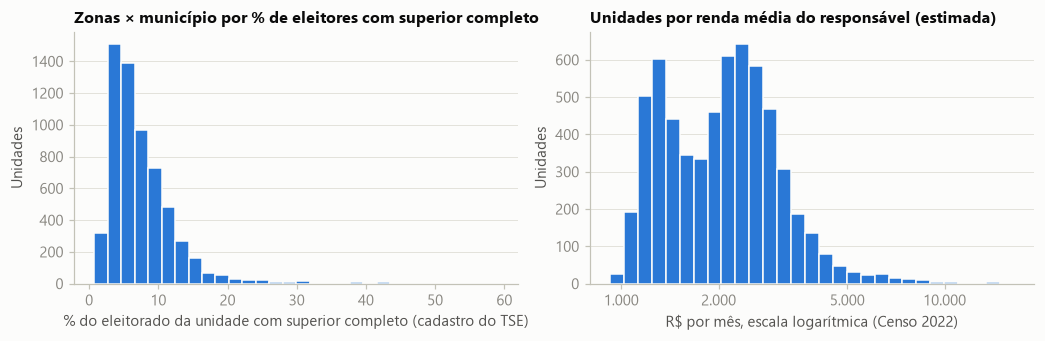

Correlação entre superior completo e log da renda: 0,75


In [5]:
fig, (eixo_esc, eixo_renda) = plt.subplots(1, 2, figsize=(9.6, 3.2))
eixo_esc.hist(100 * zonas["pc_esc_superior"], bins=30, color=COR, edgecolor=COR_FUNDO, linewidth=1)
eixo_esc.set_title("Zonas × município por % de eleitores com superior completo")
eixo_esc.set_xlabel("% do eleitorado da unidade com superior completo (cadastro do TSE)")
eixo_esc.set_ylabel("Unidades")

renda = zonas["renda_media_resp_area"]
eixo_renda.hist(renda, bins=np.geomspace(renda.min(), renda.max(), 30), color=COR, edgecolor=COR_FUNDO, linewidth=1)
eixo_renda.set_xscale("log")
marcas = [m for m in (500, 1000, 2000, 5000, 10000) if renda.min() <= m <= renda.max()]
eixo_renda.set_xticks(marcas, [numero(m, 0) for m in marcas])
eixo_renda.minorticks_off()
eixo_renda.set_title("Unidades por renda média do responsável (estimada)")
eixo_renda.set_xlabel("R$ por mês, escala logarítmica (Censo 2022)")
eixo_renda.set_ylabel("Unidades")
for eixo in (eixo_esc, eixo_renda):
    eixo.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

print("Correlação entre superior completo e log da renda:", numero(zonas["pc_esc_superior"].corr(zonas["log_renda"]), 2))

## Voto × escolaridade e × renda

As unidades são ordenadas pelo percentual de eleitores com superior completo (ou
pela renda) e divididas em cinco grupos com o mesmo número de **eleitores**. Em
cada grupo, o percentual é a soma dos votos do partido sobre a soma dos votos
válidos.

escolaridade: Q1: 0,7 a 4,6 | Q2: 4,6 a 6,8 | Q3: 6,8 a 10,1 | Q4: 10,1 a 15,0 | Q5: 15,0 a 59,1


,Q1,Q2,Q3,Q4,Q5,Total
partido,,,,,,
PT,"61,1","55,7","47,1","40,1","38,7","48,4"
PL,"33,0","37,0","44,8","51,0","49,8","43,2"
MDB,"2,6","3,2","4,1","4,6","6,1","4,2"
PDT,"2,5","3,0","2,9","3,0","3,7","3,0"
Outros,"0,8","1,0","1,1","1,2","1,6","1,2"


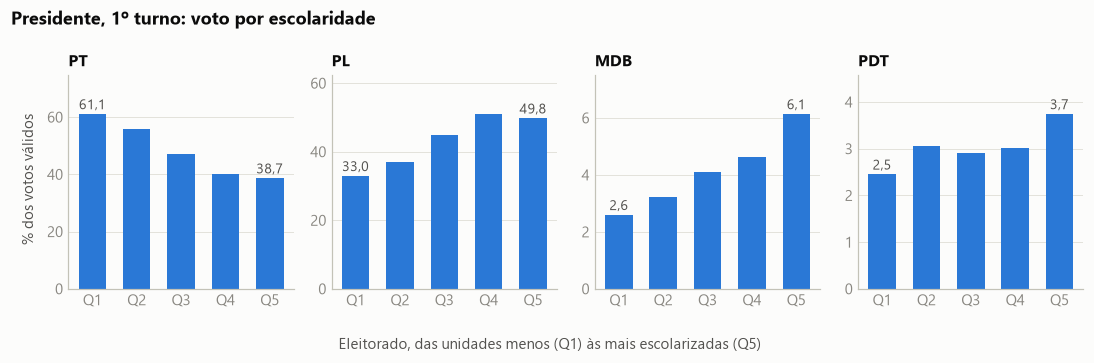

,Q1,Q2,Q3,Q4,Q5,Total
partido,,,,,,
PT,"63,0","57,8","49,2","42,4","42,8","50,9"
PL,"37,0","42,2","50,8","57,6","57,2","49,1"


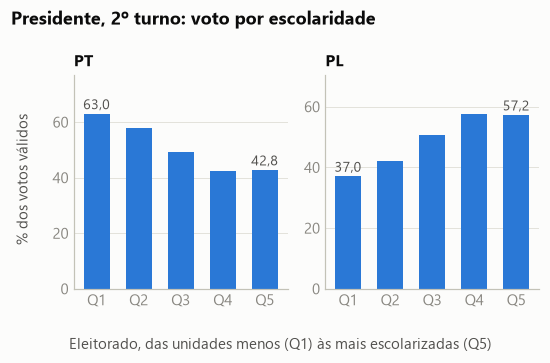

,Q1,Q2,Q3,Q4,Q5,Total
partido,,,,,,
PL,"13,1","14,5","16,6","18,1","20,4","16,5"
PT,"11,4","12,9","12,4","11,7","11,5","12,0"
UNIÃO,"11,1","10,9","8,5","8,6","7,5","9,3"
PP,"10,6","8,0","7,6","7,2","6,1","7,9"
PSD,"8,6","8,5","7,5","7,5","5,7","7,5"
MDB,"8,6","7,8","7,7","7,1","5,1","7,2"
REPUBLICANOS,"7,4","6,9","7,0","7,1","6,2","6,9"
PSB,"3,9","4,1","3,7","3,2","4,1","3,8"
PSOL,"1,6","2,5","3,0","3,4","7,0","3,5"


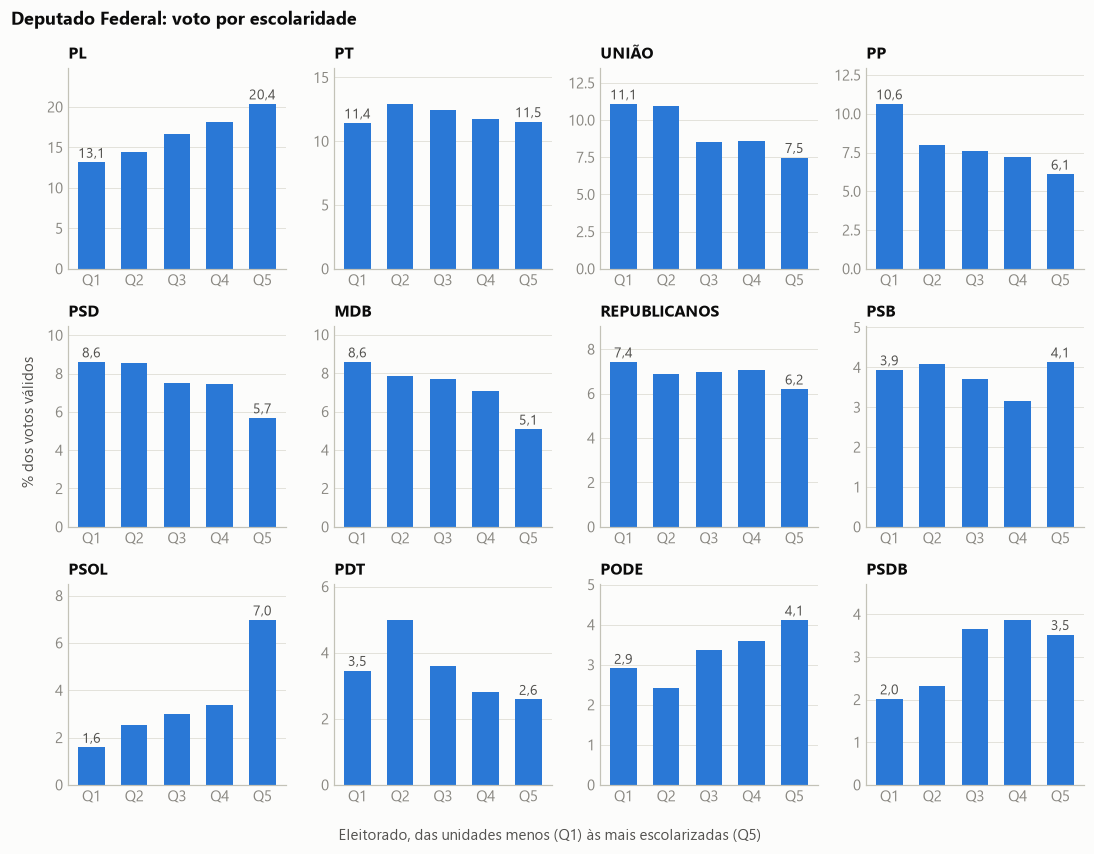

renda: Q1: 923 a 1.669 | Q2: 1.669 a 2.291 | Q3: 2.291 a 2.820 | Q4: 2.822 a 3.646 | Q5: 3.646 a 16.369


,Q1,Q2,Q3,Q4,Q5,Total
partido,,,,,,
PT,"70,7","51,7","43,2","37,6","39,4","48,4"
PL,"24,0","41,0","48,4","53,4","48,9","43,2"
MDB,"1,9","3,4","4,4","4,8","6,2","4,2"
PDT,"2,7","2,9","2,9","2,9","3,9","3,0"
Outros,"0,7","1,0","1,1","1,3","1,7","1,2"


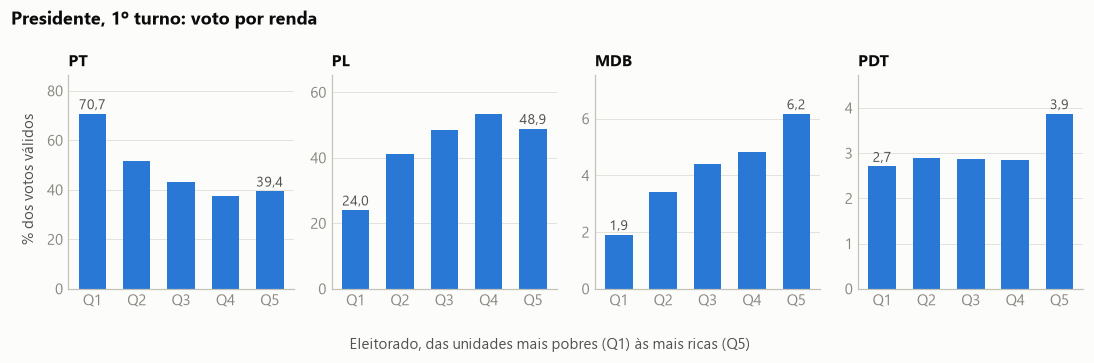

,Q1,Q2,Q3,Q4,Q5,Total
partido,,,,,,
PT,"73,0","53,7","45,2","39,8","43,6","50,9"
PL,"27,0","46,3","54,8","60,2","56,4","49,1"


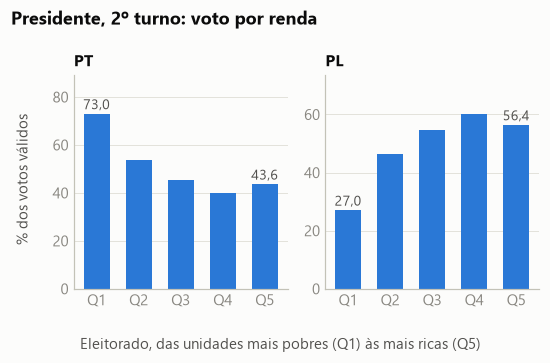

,Q1,Q2,Q3,Q4,Q5,Total
partido,,,,,,
PL,"11,0","14,7","17,0","20,7","19,5","16,5"
PT,"11,8","12,6","12,3","11,6","11,7","12,0"
UNIÃO,"12,4","10,4","8,4","7,3","8,0","9,3"
PP,"11,5","8,5","7,3","6,6","5,5","7,9"
PSD,"10,1","7,5","6,9","7,3","5,8","7,5"
MDB,"8,5","7,5","7,7","7,3","5,2","7,2"
REPUBLICANOS,"7,4","7,3","7,1","6,4","6,3","6,9"
PSB,"4,7","4,0","3,3","2,8","4,1","3,8"
PSOL,"0,6","2,3","3,2","3,9","7,5","3,5"


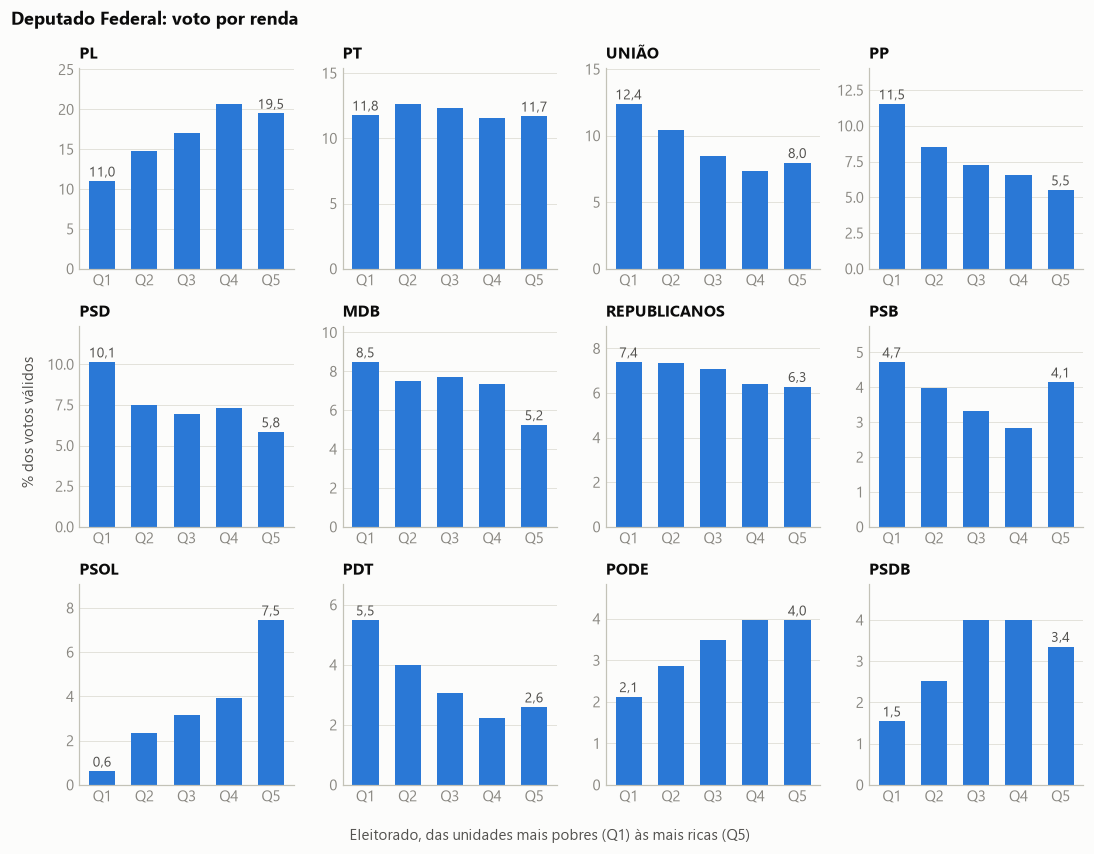

In [6]:
def quintil_por_eleitorado(variavel: pd.Series, peso: pd.Series) -> pd.Series:
    """Cinco grupos com o mesmo peso (eleitores), do menor ao maior valor de `variavel`."""
    ordem = variavel.sort_values().index
    acumulado = peso.loc[ordem].cumsum() / peso.sum()
    grupo = np.minimum((acumulado - 1e-12) * 5, 4.999).astype(int)
    return pd.Series(pd.Categorical([QUINTIS[g] for g in grupo], categories=QUINTIS), index=ordem).reindex(variavel.index)


def voto_por_quintil(df: pd.DataFrame, disputa: str, variavel: str) -> pd.DataFrame:
    """% dos votos válidos de cada partido em cada quinto do eleitorado, ordenado por `variavel`."""
    votos = votos_por_partido(df, disputa)
    quintil = quintil_por_eleitorado(df[variavel], df["qt_eleitores_perfil"])
    soma = votos.groupby(quintil, observed=True).sum()
    tabela = (100 * soma.div(soma.sum(axis=1), axis=0)).T
    tabela["Total"] = 100 * votos.sum() / votos.sum().sum()
    return tabela.rename_axis(index="partido", columns=None)


def grafico_quintis(tabela: pd.DataFrame, titulo: str, rotulo_x: str) -> None:
    """Um painel por partido; a escala vertical é a de cada partido, a partir de zero."""
    partidos = [p for p in tabela.index if p != "Outros"]
    ncol = min(4, len(partidos))
    nlin = -(-len(partidos) // ncol)
    fig, eixos = plt.subplots(nlin, ncol, figsize=(2.5 * ncol, 2.3 * nlin + 0.9), squeeze=False)
    for eixo, partido in zip(eixos.flat, partidos):
        valores = tabela.loc[partido, QUINTIS]
        eixo.bar(QUINTIS, valores, width=0.62, color=COR)
        eixo.set_title(partido)
        eixo.set_ylim(0, valores.max() * 1.22)
        eixo.grid(axis="x", visible=False)
        eixo.tick_params(length=0)
        for i in (0, 4):
            eixo.annotate(numero(valores.iloc[i]), (i, valores.iloc[i]), xytext=(0, 3),
                          textcoords="offset points", ha="center", fontsize=9, color=COR_TINTA_2)
    for eixo in eixos.flat[len(partidos):]:
        eixo.set_visible(False)
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.supxlabel(rotulo_x, fontsize=9.5, color=COR_TINTA_2)
    fig.supylabel("% dos votos válidos", fontsize=9.5, color=COR_TINTA_2)
    fig.tight_layout()
    plt.show()


for variavel, rotulo, legenda_x in [
    ("pc_esc_superior", "escolaridade", "Eleitorado, das unidades menos (Q1) às mais escolarizadas (Q5)"),
    ("renda_media_resp_area", "renda", "Eleitorado, das unidades mais pobres (Q1) às mais ricas (Q5)"),
]:
    q = quintil_por_eleitorado(zonas[variavel], zonas["qt_eleitores_perfil"])
    faixas = zonas.groupby(q, observed=True)[variavel].agg(["min", "max"])
    fmt = (lambda v: numero(100 * v)) if variavel == "pc_esc_superior" else (lambda v: numero(v, 0))
    print(f"{rotulo}: " + " | ".join(f"{g}: {fmt(r['min'])} a {fmt(r['max'])}" for g, r in faixas.iterrows()))
    for disputa, nome in DISPUTAS.items():
        tabela = voto_por_quintil(zonas, disputa, variavel)
        display(tabela.style.format(precision=1, decimal=",").set_caption(f"{nome}: % dos votos válidos por {rotulo}"))
        grafico_quintis(tabela, f"{nome}: voto por {rotulo}", legenda_x)

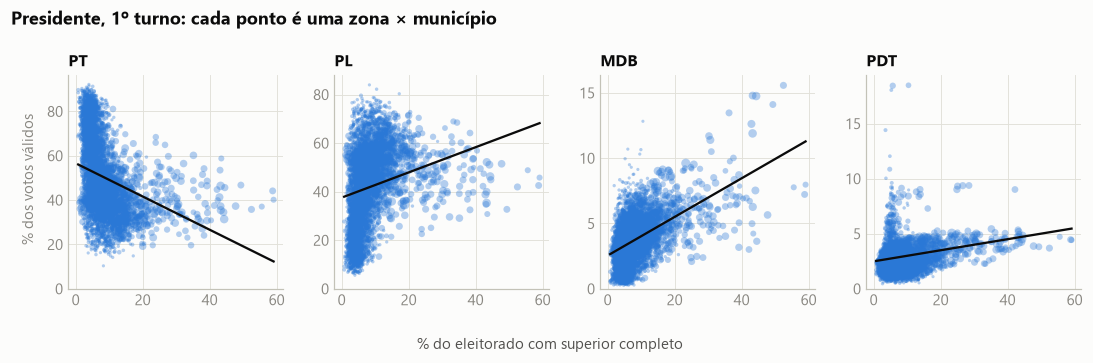

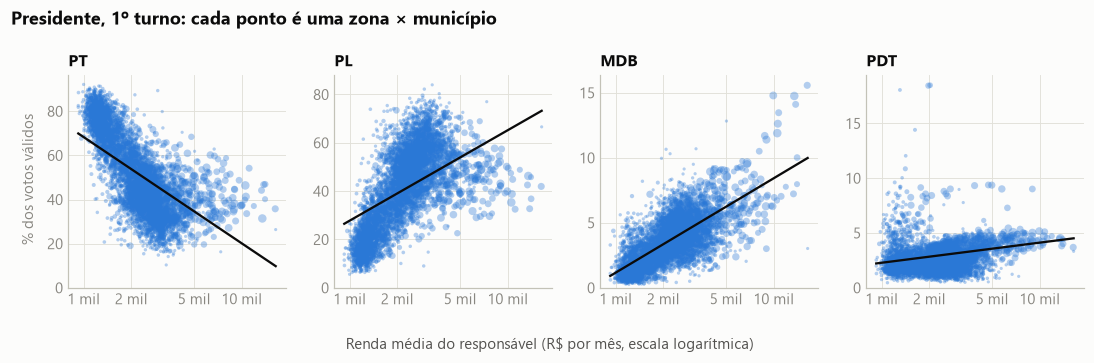

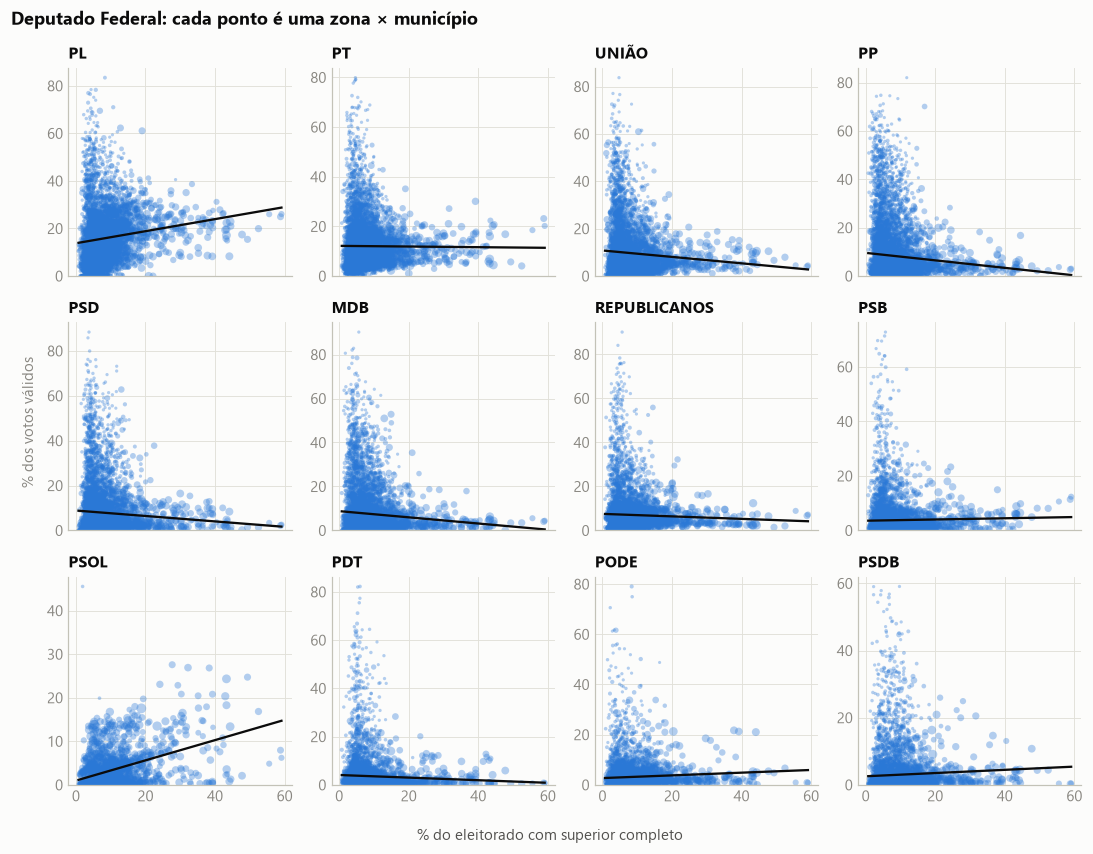

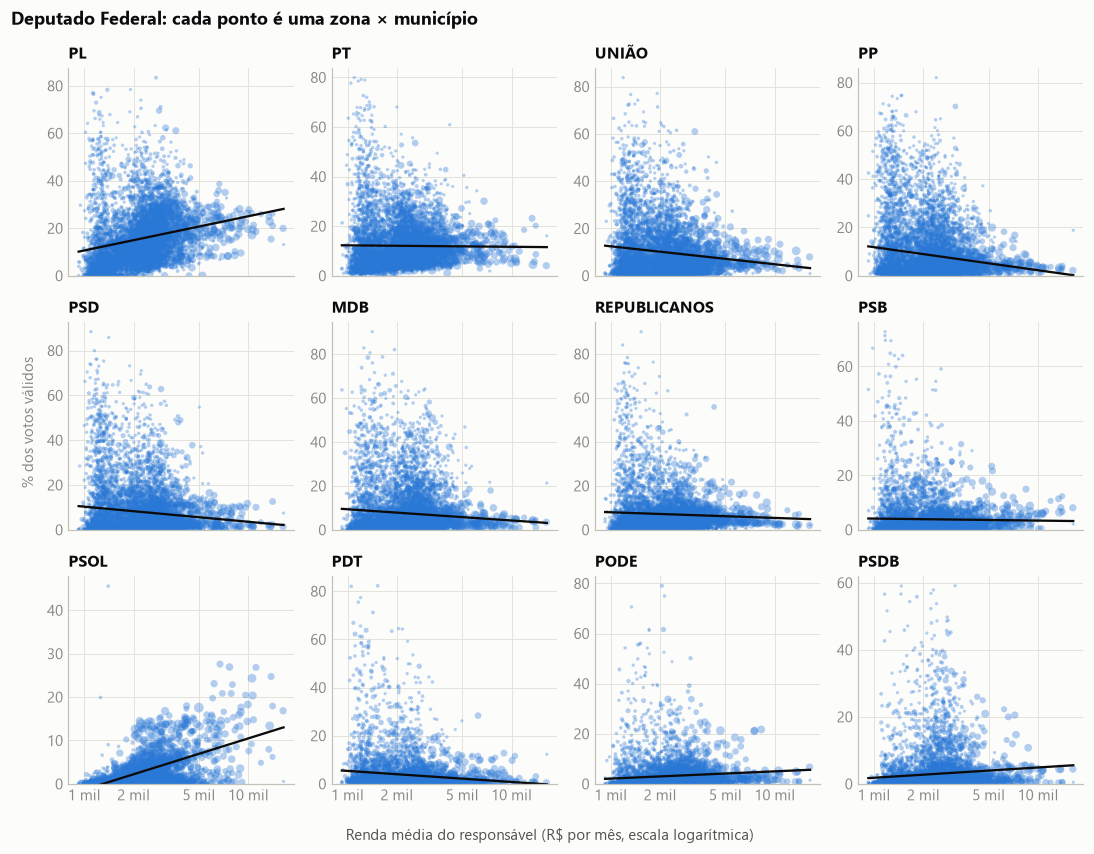

In [7]:
def grafico_dispersao(df: pd.DataFrame, disputa: str, x: pd.Series, rotulo_x: str, titulo: str, log_x: bool = False) -> None:
    """Um painel por partido; cada ponto é uma unidade (área proporcional aos votos válidos)."""
    votos = votos_por_partido(df, disputa)
    validos = votos.sum(axis=1)
    partidos = [p for p in votos.columns if p != "Outros"]
    ncol = min(4, len(partidos))
    nlin = -(-len(partidos) // ncol)
    fig, eixos = plt.subplots(nlin, ncol, figsize=(2.5 * ncol, 2.3 * nlin + 0.9), squeeze=False, sharex=True)
    for eixo, partido in zip(eixos.flat, partidos):
        y = 100 * votos[partido] / validos
        ok = x.notna() & y.notna() & (validos > 0)
        eixo.scatter(x[ok], y[ok], s=4 + 40 * validos[ok] / validos.max(), color=COR, alpha=0.35, edgecolor="none")
        xs = np.log10(x[ok]) if log_x else x[ok]
        inclinacao, intercepto = np.polyfit(xs, y[ok], 1, w=np.sqrt(validos[ok]))
        pontas = np.array([xs.min(), xs.max()])
        eixo.plot(10 ** pontas if log_x else pontas, intercepto + inclinacao * pontas, color=COR_TINTA, linewidth=1.5)
        if log_x:
            eixo.set_xscale("log")
            marcas = [m for m in (500, 1000, 2000, 5000, 10000) if x[ok].min() <= m <= x[ok].max()]
            eixo.set_xticks(marcas, [f"{m / 1000:g} mil" for m in marcas])
            eixo.minorticks_off()
        eixo.set_title(partido)
        eixo.set_ylim(bottom=0)
        eixo.tick_params(length=0)
    for eixo in eixos.flat[len(partidos):]:
        eixo.set_visible(False)
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.supxlabel(rotulo_x, fontsize=9.5, color=COR_TINTA_2)
    fig.supylabel("% dos votos válidos", fontsize=9.5, color=COR_SUAVE)
    fig.tight_layout()
    plt.show()


for disputa in [d for d in ("pres_t1", "depfed_t1") if d in DISPUTAS]:
    grafico_dispersao(zonas, disputa, 100 * zonas["pc_esc_superior"], "% do eleitorado com superior completo",
                      f"{DISPUTAS[disputa]}: cada ponto é uma zona × município")
    grafico_dispersao(zonas, disputa, zonas["renda_media_resp_area"], "Renda média do responsável (R$ por mês, escala logarítmica)",
                      f"{DISPUTAS[disputa]}: cada ponto é uma zona × município", log_x=True)

## Regressão

Uma regressão por partido, ponderada pelos votos válidos de cada unidade, com
**efeito fixo de UF** e erro padrão agrupado por município. A variável explicada é
o percentual dos votos válidos do partido; os preditores são padronizados, então
cada coeficiente é a variação, **em pontos percentuais, para um desvio-padrão a
mais** do preditor, mantidos os outros e a UF.

Efeito fixo de município não é possível: a maioria dos municípios tem uma unidade
só. O efeito fixo de UF compara unidades dentro do mesmo estado.

Escolaridade e renda andam juntas (ver a correlação acima): os dois coeficientes
dividem um efeito em boa parte comum. Vale olhar o sinal e a ordem de grandeza.

,Superior completo,Renda (log),Idade média,% de mulheres,R2,n
partido,,,,,,
PT,"1,8 [0,9; 2,7]","-6,6 [-8,1; -5,1]","0,2 [-0,9; 1,2]","-0,9 [-1,9; 0,1]","0,70",6102
PL,"-1,9 [-2,8; -1,0]","5,5 [3,9; 7,0]","-0,2 [-1,2; 0,8]","0,0 [-1,1; 1,1]","0,63",6102
MDB,"0,1 [-0,0; 0,2]","0,5 [0,4; 0,7]","0,2 [0,0; 0,4]","0,4 [0,3; 0,4]","0,78",6102
PDT,"-0,1 [-0,1; 0,0]","0,5 [0,3; 0,6]","-0,1 [-0,2; -0,0]","0,4 [0,3; 0,5]","0,71",6102


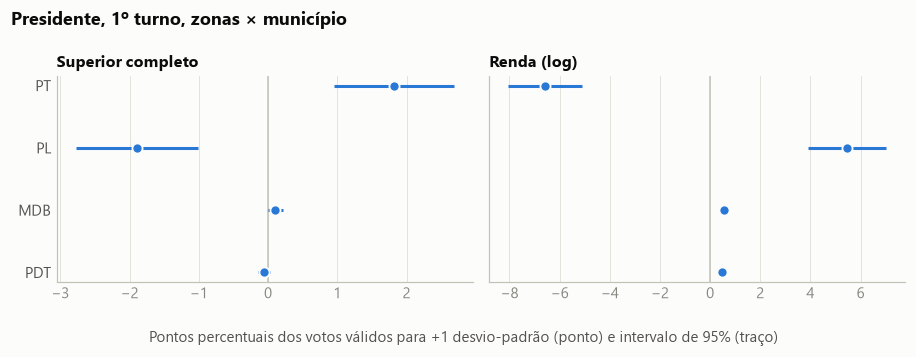

,Superior completo,Renda (log),Idade média,% de mulheres,R2,n
partido,,,,,,
PT,"2,1 [1,1; 3,0]","-6,3 [-7,9; -4,7]","0,3 [-0,7; 1,4]","-0,5 [-1,6; 0,6]","0,67",6102
PL,"-2,1 [-3,0; -1,1]","6,3 [4,7; 7,9]","-0,3 [-1,4; 0,7]","0,5 [-0,6; 1,6]","0,67",6102


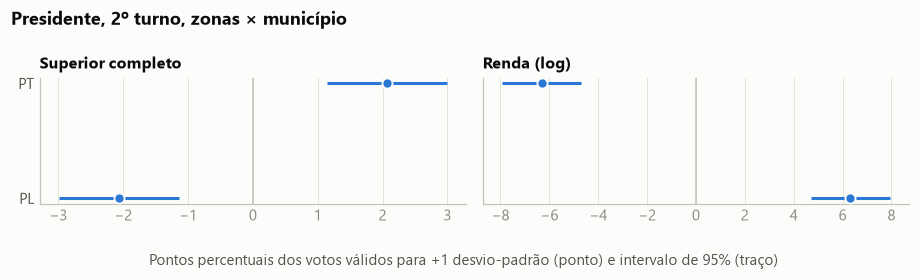

,Superior completo,Renda (log),Idade média,% de mulheres,R2,n
partido,,,,,,
PL,"-0,4 [-0,9; 0,2]","2,1 [1,2; 2,9]","0,6 [0,1; 1,1]","-0,6 [-1,1; -0,0]","0,37",6102
PT,"0,2 [-0,5; 0,8]","-0,9 [-1,7; -0,1]","-0,9 [-1,6; -0,1]","1,2 [0,3; 2,0]","0,33",6102
UNIÃO,"0,0 [-0,5; 0,5]","-0,7 [-1,6; 0,3]","-0,4 [-1,0; 0,2]","-0,1 [-0,6; 0,4]","0,18",6102
PP,"0,5 [-0,1; 1,0]","-1,6 [-2,3; -0,9]","0,8 [0,3; 1,3]","-0,9 [-1,3; -0,5]","0,29",6102
PSD,"-0,2 [-0,7; 0,2]","0,1 [-0,7; 0,8]","0,5 [0,0; 1,0]","-1,5 [-2,0; -1,0]","0,29",6102
MDB,"-0,3 [-0,8; 0,1]","-0,7 [-1,3; 0,0]","0,6 [0,2; 1,1]","-0,8 [-1,3; -0,3]","0,41",6102
REPUBLICANOS,"-0,4 [-0,8; 0,1]","-0,4 [-1,0; 0,1]","-0,4 [-0,7; -0,0]","0,8 [0,4; 1,3]","0,31",6102
PSB,"-0,1 [-0,3; 0,2]","0,3 [-0,1; 0,7]","0,3 [0,1; 0,5]","0,2 [-0,0; 0,5]","0,34",6102
PSOL,"-0,1 [-0,4; 0,2]","1,1 [0,6; 1,6]","0,6 [0,2; 1,0]","1,1 [0,6; 1,5]","0,68",6102


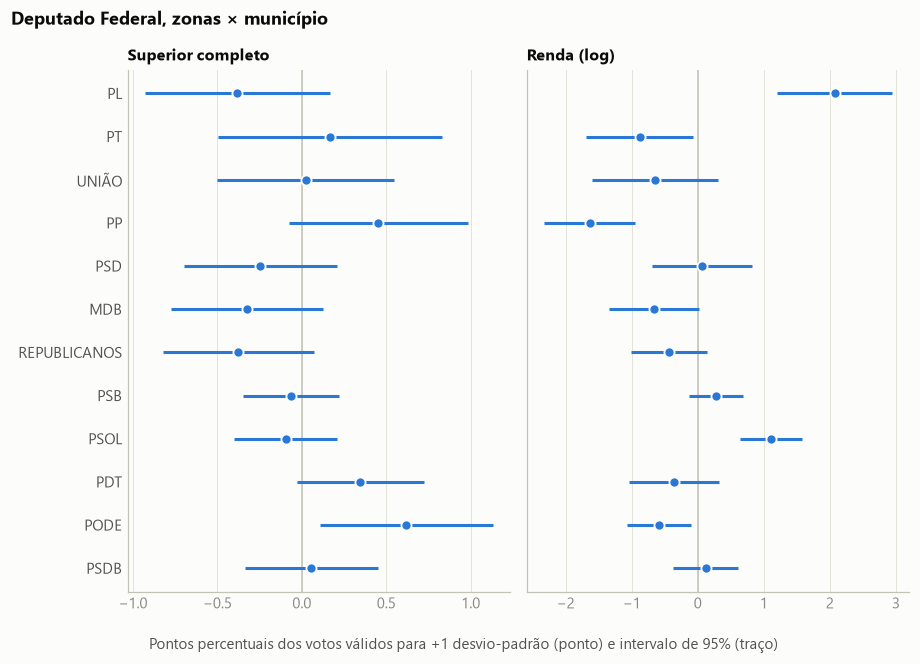

In [8]:
ROTULOS = {
    "pc_esc_superior": "Superior completo",
    "log_renda": "Renda (log)",
    "idade_media": "Idade média",
    "pc_feminino": "% de mulheres",
}
PREDITORES = list(ROTULOS)


def regressao(df: pd.DataFrame, disputa: str, preditores: list[str] = PREDITORES) -> pd.DataFrame:
    """Uma regressão ponderada por partido, com efeito fixo de UF e erro agrupado por município."""
    votos = votos_por_partido(df, disputa)
    validos = votos.sum(axis=1)
    ufs = pd.get_dummies(df["sg_uf"], drop_first=True, dtype=float)
    linhas = []
    for partido in votos.columns.drop("Outros", errors="ignore"):
        base = df[preditores].assign(y=100 * votos[partido] / validos, peso=validos)
        base = base.replace([np.inf, -np.inf], np.nan).dropna()
        base = base.loc[base["peso"] > 0]
        z = (base[preditores] - base[preditores].mean()) / base[preditores].std()
        X = sm.add_constant(pd.concat([z, ufs.loc[base.index]], axis=1))
        ajuste = sm.WLS(base["y"], X, weights=base["peso"]).fit(
            cov_type="cluster", cov_kwds={"groups": pd.factorize(df.loc[base.index, "cd_mun"])[0]}
        )
        ic = ajuste.conf_int()
        for preditor in preditores:
            linhas.append({
                "partido": partido, "preditor": preditor, "coef": ajuste.params[preditor],
                "ic_min": ic.loc[preditor, 0], "ic_max": ic.loc[preditor, 1],
                "p_valor": ajuste.pvalues[preditor], "r2": ajuste.rsquared, "n": int(ajuste.nobs),
            })
    return pd.DataFrame(linhas)


def tabela_coeficientes(coefs: pd.DataFrame) -> pd.DataFrame:
    """Coeficientes (p.p. por desvio-padrão) com o intervalo de 95%, mais R² e n."""
    texto = coefs.apply(lambda r: f"{numero(r['coef'])} [{numero(r['ic_min'])}; {numero(r['ic_max'])}]", axis=1)
    larga = coefs.assign(texto=texto).pivot(index="partido", columns="preditor", values="texto")
    larga = larga[coefs["preditor"].unique()].rename(columns=ROTULOS).loc[coefs["partido"].unique()]
    resumo = coefs.groupby("partido")[["r2", "n"]].first()
    larga = larga.assign(R2=resumo["r2"].map(lambda v: numero(v, 2)), n=resumo["n"])
    return larga.rename_axis(index="partido", columns=None)


def grafico_coeficientes(coefs: pd.DataFrame, preditores: list[str], titulo: str) -> None:
    """Coeficiente e intervalo de 95% por partido, um painel por preditor."""
    partidos = list(coefs["partido"].unique())[::-1]
    fig, eixos = plt.subplots(1, len(preditores), figsize=(3.6 * len(preditores) + 1.2, 0.36 * len(partidos) + 1.7),
                              sharey=True, squeeze=False)
    for eixo, preditor in zip(eixos.flat, preditores):
        d = coefs.loc[coefs["preditor"] == preditor].set_index("partido").loc[partidos]
        eixo.axvline(0, color=COR_EIXO, linewidth=1)
        eixo.hlines(d.index, d["ic_min"], d["ic_max"], color=COR, linewidth=2)
        eixo.scatter(d["coef"], d.index, s=44, color=COR, edgecolor=COR_FUNDO, linewidth=1.2, zorder=3)
        eixo.set_title(ROTULOS[preditor])
        eixo.grid(axis="y", visible=False)
        eixo.tick_params(length=0)
        eixo.tick_params(axis="y", labelcolor=COR_TINTA_2)
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.supxlabel("Pontos percentuais dos votos válidos para +1 desvio-padrão (ponto) e intervalo de 95% (traço)",
                  fontsize=9.5, color=COR_TINTA_2)
    fig.tight_layout()
    plt.show()


coefs = {d: regressao(zonas, d) for d in DISPUTAS}
for disputa, nome in DISPUTAS.items():
    display(tabela_coeficientes(coefs[disputa]).style.set_caption(f"{nome}, todas as unidades"))
    grafico_coeficientes(coefs[disputa], ["pc_esc_superior", "log_renda"], f"{nome}, zonas × município")

### Cada faixa de escolaridade, com p-valor

As quatro faixas somam 100% do eleitorado da unidade, então não entram juntas no
mesmo modelo (colinearidade perfeita). Aqui cada faixa entra **sozinha**, com os
mesmos controles (renda, idade média, % de mulheres) e a UF fixa: são quatro
regressões por partido. O coeficiente é a variação em pontos percentuais do voto
para +1 desvio-padrão do peso daquela faixa no eleitorado.

Como são muitos testes (partidos × faixas), além do p-valor da tabela mostro o
**p ajustado de Holm**, calculado dentro de cada disputa. Asteriscos no p ajustado:
`***` < 0,001, `**` < 0,01, `*` < 0,05.

,Até fundamental incompleto,Fundamental completo ou médio incompleto,Médio completo ou superior incompleto,Superior completo
partido,,,,
PT,"4,1*** (p < 0,001)","0,2 (p 0,707)","-4,1*** (p < 0,001)","1,8*** (p < 0,001)"
PL,"-3,5** (p < 0,001)","-0,4 (p 0,452)","4,0*** (p < 0,001)","-1,9*** (p < 0,001)"
MDB,"-0,3 (p 0,031)","0,1 (p 0,068)","0,0 (p 0,805)","0,1 (p 0,056)"
PDT,"-0,2** (p < 0,001)","0,1* (p 0,003)","0,0 (p 0,145)","-0,1 (p 0,174)"


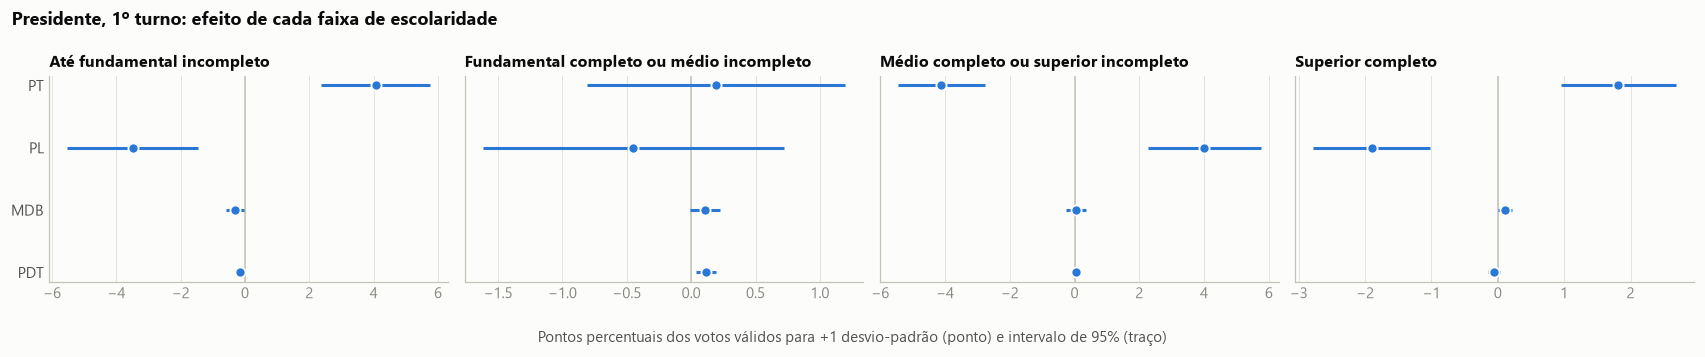

,Até fundamental incompleto,Fundamental completo ou médio incompleto,Médio completo ou superior incompleto,Superior completo
partido,,,,
PT,"4,0*** (p < 0,001)","0,3 (p 0,652)","-4,3*** (p < 0,001)","2,1*** (p < 0,001)"
PL,"-4,0*** (p < 0,001)","-0,3 (p 0,652)","4,3*** (p < 0,001)","-2,1*** (p < 0,001)"


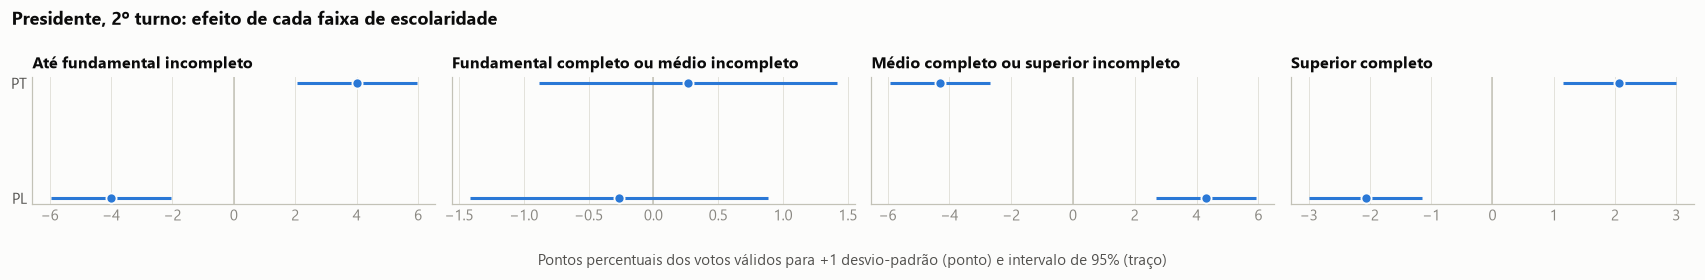

,Até fundamental incompleto,Fundamental completo ou médio incompleto,Médio completo ou superior incompleto,Superior completo
partido,,,,
PL,"-0,5 (p 0,384)","0,1 (p 0,874)","0,6 (p 0,316)","-0,4 (p 0,172)"
PT,"0,6 (p 0,093)","-0,0 (p 0,955)","-0,5 (p 0,072)","0,2 (p 0,622)"
UNIÃO,"0,5 (p 0,266)","0,2 (p 0,401)","-0,6 (p 0,125)","0,0 (p 0,935)"
PP,"0,7 (p 0,030)","-0,5 (p 0,033)","-0,4 (p 0,116)","0,5 (p 0,093)"
PSD,"1,1 (p 0,005)","-0,1 (p 0,667)","-0,5 (p 0,092)","-0,2 (p 0,285)"
MDB,"1,5** (p < 0,001)","-0,3 (p 0,191)","-0,5 (p 0,033)","-0,3 (p 0,159)"
REPUBLICANOS,"-0,4 (p 0,143)","0,3 (p 0,090)","0,3 (p 0,248)","-0,4 (p 0,099)"
PSB,"-0,7 (p 0,022)","0,0 (p 0,898)","0,5 (p 0,041)","-0,1 (p 0,669)"
PSOL,"0,3 (p 0,445)","0,7 (p 0,005)","-0,8 (p 0,049)","-0,1 (p 0,541)"


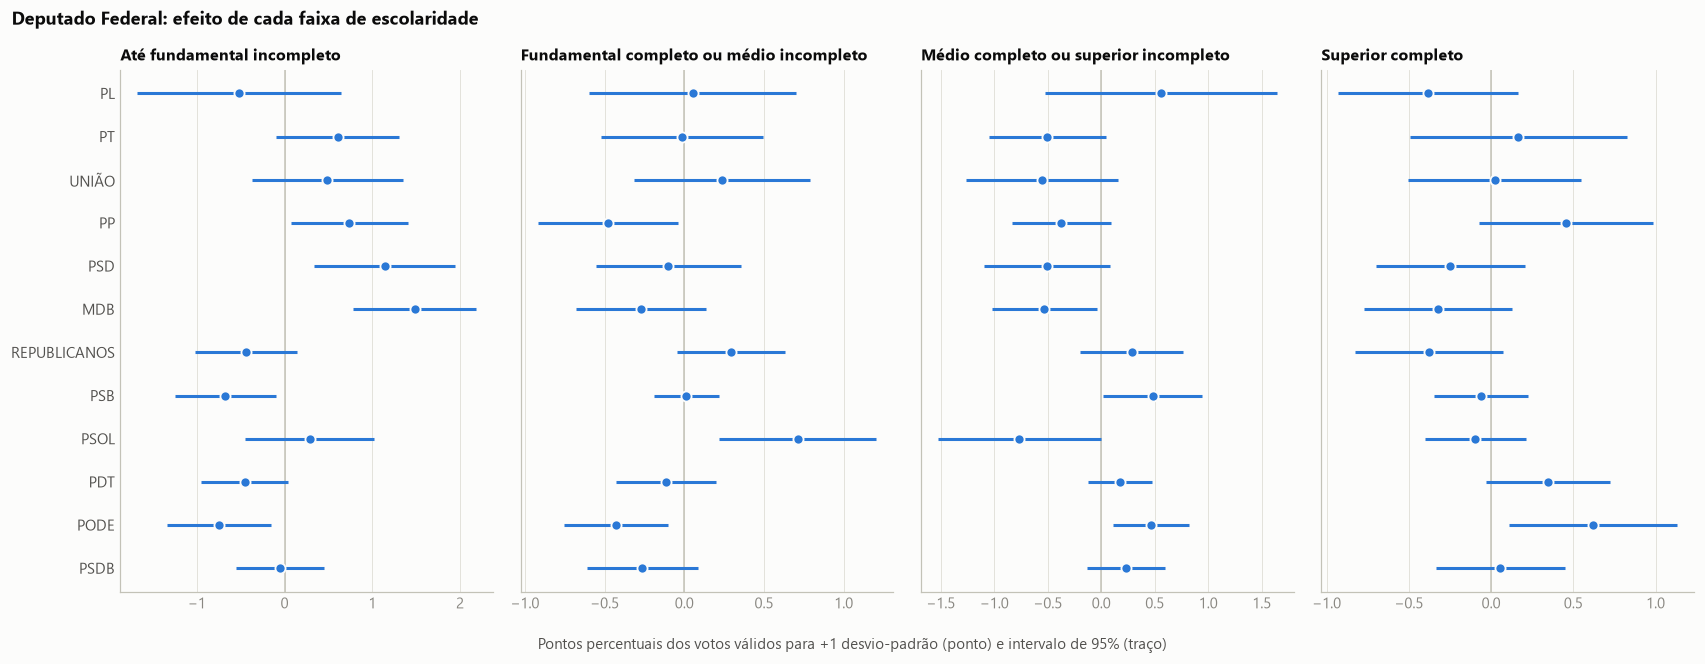

significativos (Holm < 0,05)  \
                     faixa                                                                    
Presidente, 1º turno Até fundamental incompleto                                           3   
                     Fundamental completo ou médio incompleto                             1   
                     Médio completo ou superior incompleto                                2   
                     Superior completo                                                    2   
Presidente, 2º turno Até fundamental incompleto                                           2   
                     Fundamental completo ou médio incompleto                             0   
                     Médio completo ou superior incompleto                                2   
                     Superior completo                                                    2   
Deputado Federal     Até fundamental incompleto                                           1   
                     Fundamental completo ou médio incompleto                             0   
                     Médio completo ou superior incompleto                                0   
                     Superior completo                                                    0   

                                                               testes  
                     faixa                                             
Presidente, 1º turno Até fundamental incompleto                     4  
                     Fundamental completo ou médio incompleto       4  
                     Médio completo ou superior incompleto          4  
                     Superior completo                              4  
Presidente, 2º turno Até fundamental incompleto                     2  
                     Fundamental completo ou médio incompleto       2  
                     Médio completo ou superior incompleto          2  
                     Superior completo                              2  
Deputado Federal     Até fundamental incompleto                    12  
                     Fundamental completo ou médio incompleto      12  
                     Médio completo ou superior incompleto         12  
                     Superior completo                             12

In [9]:
from statsmodels.stats.multitest import multipletests

FAIXAS_ESC = {
    "pc_esc_ate_fund_incompleto": "Até fundamental incompleto",
    "pc_esc_fund_completo": "Fundamental completo ou médio incompleto",
    "pc_esc_medio_completo": "Médio completo ou superior incompleto",
    "pc_esc_superior": "Superior completo",
}
ROTULOS.update(FAIXAS_ESC)


def estrelas(p: float) -> str:
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""


def regressao_por_faixa(df: pd.DataFrame, disputa: str) -> pd.DataFrame:
    """Uma regressão por partido e por faixa de escolaridade (cada faixa sozinha, com os controles)."""
    controles = ["log_renda", "idade_media", "pc_feminino"]
    partes = []
    for faixa in FAIXAS_ESC:
        r = regressao(df, disputa, [faixa, *controles]).query("preditor == @faixa")
        partes.append(r.assign(faixa=faixa))
    coefs = pd.concat(partes, ignore_index=True)
    coefs["p_holm"] = multipletests(coefs["p_valor"], method="holm")[1]
    return coefs


def tabela_faixas(coefs: pd.DataFrame) -> pd.DataFrame:
    """Coeficiente (p.p. por desvio-padrão) e p ajustado, partido × faixa."""
    texto = coefs.apply(
        lambda r: f"{numero(r['coef'])}{estrelas(r['p_holm'])} (p {'< 0,001' if r['p_valor'] < 0.001 else numero(r['p_valor'], 3)})",
        axis=1,
    )
    larga = coefs.assign(texto=texto).pivot(index="partido", columns="faixa", values="texto")
    larga = larga[list(FAIXAS_ESC)].rename(columns=FAIXAS_ESC).loc[coefs["partido"].unique()]
    return larga.rename_axis(index="partido", columns=None)


por_faixa = {d: regressao_por_faixa(zonas, d) for d in DISPUTAS}
for disputa, nome in DISPUTAS.items():
    display(tabela_faixas(por_faixa[disputa]).style.set_caption(f"{nome}: coeficiente por faixa de escolaridade (p ajustado de Holm: asteriscos)"))
    grafico_coeficientes(por_faixa[disputa].assign(preditor=lambda d: d["faixa"]), list(FAIXAS_ESC),
                         f"{nome}: efeito de cada faixa de escolaridade")

resumo_sig = pd.concat({
    DISPUTAS[d]: por_faixa[d].assign(sig=lambda x: x["p_holm"] < 0.05).groupby("faixa")["sig"].agg(["sum", "size"]).rename(index=FAIXAS_ESC)
    for d in DISPUTAS
}).rename(columns={"sum": "significativos (Holm < 0,05)", "size": "testes"})
resumo_sig

### Sensibilidade: a renda medida de outras formas

A renda usada até aqui é a renda média do *responsável* pelo domicílio, por setor,
levada à zona pelos pesos do CNEFE. Os microdados da amostra do Censo (acesso
controlado) permitem medir a renda de outro jeito, para a população de 16 anos ou mais:

- **calibrada**: renda domiciliar per capita; o padrão entre setores de uma mesma área
  de ponderação vem dos setores e o nível vem dos microdados (a média da área bate com a
  dos microdados);
- **só da área de ponderação**: a renda per capita dos microdados, sem nenhum detalhe
  dentro da área (em 2.993 dos 5.570 municípios a área é o município inteiro).

A pergunta é se o coeficiente da escolaridade, o mais frágil, muda de sinal ou de
tamanho quando a renda é medida melhor. Se mudar, o resultado anterior era sensível à
imprecisão da renda.

In [10]:
if "renda_pc_cal" in zonas.columns:
    zonas["log_renda_cal"] = np.log(zonas["renda_pc_cal"])
    zonas["log_renda_ap"] = np.log(zonas["renda_pc_ap"])
    VARIANTES = {
        "log_renda": "Responsável, estimada pelos setores (a anterior)",
        "log_renda_cal": "Per capita, calibrada pelos microdados",
        "log_renda_ap": "Per capita, só da área de ponderação",
    }
    print("Correlação entre as três medidas (em log):")
    display(zonas[list(VARIANTES)].corr().round(2).rename(index=VARIANTES, columns=VARIANTES))

    linhas = []
    for disputa in [d for d in ("pres_t1", "pres_t2", "depfed_t1") if d in DISPUTAS]:
        for variante, rotulo in VARIANTES.items():
            r = regressao(zonas, disputa, ["pc_esc_superior", variante, "idade_media", "pc_feminino"])
            for _, linha in r.query("preditor in ['pc_esc_superior', @variante]").iterrows():
                linhas.append({
                    "disputa": DISPUTAS[disputa], "partido": linha["partido"], "renda medida como": rotulo,
                    "variável": "Superior completo" if linha["preditor"] == "pc_esc_superior" else "Renda (log)",
                    "coef": linha["coef"], "ic_min": linha["ic_min"], "ic_max": linha["ic_max"], "r2": linha["r2"],
                })
    sens = pd.DataFrame(linhas)
    sens["texto"] = sens.apply(lambda r: f"{numero(r['coef'])} [{numero(r['ic_min'])}; {numero(r['ic_max'])}]", axis=1)
    escolhidos = sens[(sens["partido"].isin(["PT", "PL", "PP", "PSOL"]))]
    tabela_sens = escolhidos.pivot_table(index=["disputa", "partido", "renda medida como"], columns="variável",
                                         values="texto", aggfunc="first")
    r2 = escolhidos.groupby(["disputa", "partido", "renda medida como"])["r2"].first().map(lambda v: numero(v, 2))
    display(tabela_sens.assign(R2=r2).rename_axis(columns=None).style.set_caption(
        "Coeficientes (p.p. por desvio-padrão) com a renda medida de três formas"))
else:
    print("Sem as colunas de renda calibrada: rodar scripts/11_setor_ap.R, scripts/12_celulas_censo_amostra.py e o script 10.")

Correlação entre as três medidas (em log):


,"Responsável, estimada pelos setores (a anterior)","Per capita, calibrada pelos microdados","Per capita, só da área de ponderação"
"Responsável, estimada pelos setores (a anterior)",1.00,0.96,0.96
"Per capita, calibrada pelos microdados",0.96,1.00,1.00
"Per capita, só da área de ponderação",0.96,1.00,1.00


### Por porte do município

O mesmo modelo só com as unidades dos municípios com várias zonas (onde a renda
varia dentro do município) e só com os de zona única (onde a renda é a do município
inteiro). Se a história for a mesma, o sinal dos coeficientes não muda.

In [11]:
portes = {}
for porte, d in zonas.groupby("porte"):
    for disputa in ("pres_t1", "depfed_t1"):
        if disputa not in DISPUTAS:
            continue
        r = regressao(d, disputa).query("preditor in ['pc_esc_superior', 'log_renda']")
        portes[(DISPUTAS[disputa], porte)] = r.pivot(index="partido", columns="preditor", values="coef").rename(columns=ROTULOS)
comparacao = pd.concat(portes, names=["disputa", "porte"])
comparacao.style.format(precision=1, decimal=",")

### Por região

Coeficiente da escolaridade e da renda em cada região, para os dois partidos
principais da disputa presidencial.

In [12]:
linhas = []
for regiao, d in zonas.groupby("regiao"):
    for disputa in [x for x in ("pres_t1",) if x in DISPUTAS]:
        r = regressao(d, disputa).query("preditor in ['pc_esc_superior', 'log_renda']")
        r = r.assign(regiao=regiao, n_regiao=len(d))
        linhas.append(r)
por_regiao = pd.concat(linhas)
por_regiao.pivot_table(index=["partido", "regiao"], columns="preditor", values="coef").rename(columns=ROTULOS).style.format(precision=1, decimal=",")